In [1]:
# Importación de librerías
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#Objetivo del proyecto. 
#Preguntas de investigación
#Data set: Exo-planetary systems discovered by NASA download from Kaggle - Sathyanarayan Rao

#Importacion de csv a df, usar relative path
df = pd.read_csv("exoplanets.csv", low_memory=False)

In [ ]:
#Data Overview. Dimensiones de la BDD, Tipos de datos

print("Número de registros:", df.shape[0])
print("Número de columnas:", df.shape[1])

# Inspección general

display(df.head())
df.info()

Número de registros: 32552
Número de columnas: 93


,Unnamed: 0,pl_name,hostname,default_flag,sy_snum,sy_pnum,discoverymethod,disc_year,disc_facility,soltype,...,sy_vmagerr2,sy_kmag,sy_kmagerr1,sy_kmagerr2,sy_gaiamag,sy_gaiamagerr1,sy_gaiamagerr2,rowupdate,pl_pubdate,releasedate
0,0,11 Com b,11 Com,1,2,1,Radial Velocity,2007,Xinglong Station,Published Confirmed,...,-0.023,2.282,0.346,-0.346,4.44038,0.003848,-0.003848,2014-05-14,2008-01,2014-05-14
1,1,11 Com b,11 Com,0,2,1,Radial Velocity,2007,Xinglong Station,Published Confirmed,...,-0.023,2.282,0.346,-0.346,4.44038,0.003848,-0.003848,2014-07-23,2011-08,2014-07-23
2,2,11 UMi b,11 UMi,0,1,1,Radial Velocity,2009,Thueringer Landessternwarte Tautenburg,Published Confirmed,...,-0.005,1.939,0.270,-0.270,4.56216,0.003903,-0.003903,2018-04-25,2011-08,2014-07-23
3,3,11 UMi b,11 UMi,1,1,1,Radial Velocity,2009,Thueringer Landessternwarte Tautenburg,Published Confirmed,...,-0.005,1.939,0.270,-0.270,4.56216,0.003903,-0.003903,2018-09-04,2017-03,2018-09-06
4,4,11 UMi b,11 UMi,0,1,1,Radial Velocity,2009,Thueringer Landessternwarte Tautenburg,Published Confirmed,...,-0.005,1.939,0.270,-0.270,4.56216,0.003903,-0.003903,2018-04-25,2009-10,2014-05-14


<class 'pandas.DataFrame'>
RangeIndex: 32552 entries, 0 to 32551
Data columns (total 93 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       32552 non-null  int64  
 1   pl_name          32552 non-null  str    
 2   hostname         32552 non-null  str    
 3   default_flag     32552 non-null  int64  
 4   sy_snum          32552 non-null  int64  
 5   sy_pnum          32552 non-null  int64  
 6   discoverymethod  32552 non-null  str    
 7   disc_year        32552 non-null  int64  
 8   disc_facility    32552 non-null  str    
 9   soltype          32552 non-null  str    
 10  pl_controv_flag  32552 non-null  int64  
 11  pl_refname       32552 non-null  str    
 12  pl_orbper        29747 non-null  float64
 13  pl_orbpererr1    28504 non-null  float64
 14  pl_orbpererr2    28503 non-null  float64
 15  pl_orbperlim     29752 non-null  float64
 16  pl_orbsmax       18177 non-null  float64
 17  pl_orbsmaxerr1   4178 n

In [4]:
# Identificar registros por planeta
print("Registros totales:", len(df))
print("Planetas únicos:", df["pl_name"].nunique())
print("Estrellas únicas:", df["hostname"].nunique())

# Identificar registros duplicados
print(" ")
print("Registros duplicados:", df.duplicated().sum()) #registros exactos
#print("Planetas duplicados", df.duplicated("pl_name").sum()) #planetas duplicadas
#print("Planetas duplicados", df.duplicated("hostname").sum()) #estrellas duplicadas

#Default flags, parámetro de aprobación por parte de NASA. Corresponde al número de planetas únicos
print(" ")
print(df["default_flag"].value_counts())

#Tipos de solución, si está publicado o es candidato a publicarse.
print(" ")
print(df["soltype"].value_counts().head(10))

#Registros controversiales
print(" ")
print(df["pl_controv_flag"].value_counts())

#Descripción de Periodo de descubrimiento
print(" ")
print(df["disc_year"].describe())

Registros totales: 32552
Planetas únicos: 5044
Estrellas únicas: 3781
 
Registros duplicados: 0
 
default_flag
0    27508
1     5044
Name: count, dtype: int64
 
soltype
Published Confirmed                               16083
Kepler Project Candidate (q1_q17_dr25_sup_koi)     2668
Kepler Project Candidate (q1_q16_koi)              2660
Kepler Project Candidate (q1_q17_dr25_koi)         2651
Kepler Project Candidate (q1_q17_dr24_koi)         2640
Kepler Project Candidate (q1_q12_koi)              2624
Kepler Project Candidate (q1_q8_koi)               2271
Published Candidate                                 771
TESS Project Candidate                              184
Name: count, dtype: int64
 
pl_controv_flag
0    32504
1       48
Name: count, dtype: int64
 
count    32552.000000
mean      2015.025068
std          3.490876
min       1989.000000
25%       2014.000000
50%       2016.000000
75%       2016.000000
max       2022.000000
Name: disc_year, dtype: float64


In [ ]:
#Identificación de valores nulos
nulls = pd.DataFrame({
    "missing_values": df.isnull().sum(),
    "missing_percentage": df.isnull().mean() * 100
})
display(nulls.sort_values(
    "missing_percentage",
    ascending=False
))

,missing_values,missing_percentage
pl_eqterr2,31044,95.367412
pl_eqterr1,31044,95.367412
st_spectype,30663,94.196977
pl_orbeccenerr2,29973,92.077292
pl_orbeccenerr1,29972,92.074220
...,...,...
sy_refname,0,0.000000
decstr,0,0.000000
dec,0,0.000000
pl_pubdate,0,0.000000


In [ ]:
#Granularidad del Data set. 
# Creación de dataset maestro llamado df_exoplants

master_columns = [#variables seleccionadas
    "pl_name",
    "hostname",
    "discoverymethod",
    "disc_year",
    "disc_facility",
    "default_flag",
    "soltype",
    "pl_controv_flag",
    "pl_orbper",
    "pl_orbsmax",
    "pl_rade",
    "pl_bmasse",
    "pl_orbeccen",
    "pl_eqt",
    "st_mass",
    "st_rad",
    "st_teff",
    "sy_snum",
    "sy_pnum"
]

# Crear dataset de trabajo
df_exoplanets = df[master_columns].copy()

# Conservar únicamente la solución predeterminada
df_exoplanets = df_exoplanets[
    df_exoplanets["default_flag"] == 1
].copy()

# Revisar dimensiones de data set (19 col x 5044 rows)
print("Dimensiones:", df_exoplanets.shape)

# Revisar estructura
df_exoplanets.info()

Dimensiones: (5044, 19)
<class 'pandas.DataFrame'>
Index: 5044 entries, 0 to 32551
Data columns (total 19 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   pl_name          5044 non-null   str    
 1   hostname         5044 non-null   str    
 2   discoverymethod  5044 non-null   str    
 3   disc_year        5044 non-null   int64  
 4   disc_facility    5044 non-null   str    
 5   default_flag     5044 non-null   int64  
 6   soltype          5044 non-null   str    
 7   pl_controv_flag  5044 non-null   int64  
 8   pl_orbper        4870 non-null   float64
 9   pl_orbsmax       2830 non-null   float64
 10  pl_rade          3898 non-null   float64
 11  pl_bmasse        2107 non-null   float64
 12  pl_orbeccen      1789 non-null   float64
 13  pl_eqt           952 non-null    float64
 14  st_mass          4284 non-null   float64
 15  st_rad           4585 non-null   float64
 16  st_teff          4678 non-null   float64
 17  sy_sn

In [9]:
#Identificación de sistemas con mayor cantidad de planetas
df_exoplanets[
    ["hostname", "sy_pnum"]
].drop_duplicates().sort_values(
    "sy_pnum", ascending=False
).head(10)

,hostname,sy_pnum
4776,KOI-351,8
31494,TRAPPIST-1,7
2124,HD 219134,6
31315,TOI-178,6
16532,Kepler-20,6
28163,Kepler-80,6
2315,HD 34445,6
6344,Kepler-11,6
3121,K2-138,6
1260,HD 10180,6


In [10]:
#Verificación de registros únicos para planetas
print("Registros:", len(df_exoplanets))

print(
    "Planetas únicos:",
    df_exoplanets["pl_name"].nunique()
)

print(
    "Sistemas únicos:",
    df_exoplanets["hostname"].nunique()
)

print(
    "Nombres de planetas duplicados:",
    df_exoplanets["pl_name"].duplicated().sum()
)

Registros: 5044
Planetas únicos: 5044
Sistemas únicos: 3781
Nombres de planetas duplicados: 0


In [11]:
#Verificación, agrupa por sistema (hostname) verifica que cada sistema tenga un número
#asignado y que se comparta entre los registros del mismo sistema/planetas. 
system_check = df_exoplanets.groupby("hostname").agg( #Agrupo by hostname
    stars_distinct=("sy_snum", "nunique"), 
    planets_distinct=("sy_pnum", "nunique")
)

display(system_check[
    (system_check["stars_distinct"] > 1) |
    (system_check["planets_distinct"] > 1)
])

,stars_distinct,planets_distinct
hostname,,


In [12]:
# 3.2 Identificar columnas categóricas, descripción
categorical_columns = df_exoplanets.select_dtypes(
    include=["object", "str", "category"]
).columns

# Número de categorías únicas por columna
for col in categorical_columns:
    print(f"\nVariable: {col}")
    print("Categorías únicas:", df_exoplanets[col].nunique())
    print(df_exoplanets[col].value_counts(dropna=False).head(15))


Variable: pl_name
Categorías únicas: 5044
pl_name
11 Com b                        1
11 UMi b                        1
14 And b                        1
14 Her b                        1
16 Cyg B b                      1
17 Sco b                        1
18 Del b                        1
1RXS J160929.1-210524 b         1
24 Boo b                        1
24 Sex b                        1
24 Sex c                        1
2M0437 b                        1
2MASS J01033563-5515561 AB b    1
2MASS J01225093-2439505 b       1
2MASS J02192210-3925225 b       1
Name: count, dtype: int64

Variable: hostname
Categorías únicas: 3781
hostname
KOI-351       8
TRAPPIST-1    7
HD 10180      6
HD 219134     6
HD 34445      6
K2-138        6
Kepler-11     6
Kepler-20     6
Kepler-80     6
TOI-178       6
55 Cnc        5
GJ 667 C      5
HD 108236     5
HD 158259     5
HD 191939     5
Name: count, dtype: int64

Variable: discoverymethod
Categorías únicas: 11
discoverymethod
Transit                      

In [ ]:
#Búsqueda de valores especiales. 
numeric_columns = df_exoplanets.select_dtypes( #Se define variable para búscar valores numéricos
    include="number"
).columns

# Valores negativos. Búsqueda de valores menores a cero
negative_values = (
    df_exoplanets[numeric_columns] < 0
).sum()

# Valores iguales a cero. Búsqueda de valores iguales a cero
zero_values = (
    df_exoplanets[numeric_columns] == 0
).sum()

# Valores infinitos. Búsqueda de valores que tienden a infinito
infinite_values = pd.Series({
    col: np.isinf(df_exoplanets[col]).sum()
    for col in numeric_columns
})

#Definición de los valores especiales buscados.
special_values = pd.DataFrame({
    "negative": negative_values,
    "zero": zero_values,
    "infinite": infinite_values
})

#Impresión en consola de los valores buscados
display(special_values)

,negative,zero,infinite
disc_year,0,0,0
default_flag,0,0,0
pl_controv_flag,0,5020,0
pl_orbper,0,0,0
pl_orbsmax,0,0,0
pl_rade,0,0,0
pl_bmasse,0,0,0
pl_orbeccen,0,390,0
pl_eqt,0,0,0
st_mass,0,0,0


In [ ]:
#Identificación de valores controversiales
df_controversiales = df_exoplanets[
    df_exoplanets["pl_controv_flag"] == 1
].copy()

print("Planetas controversiales:", len(df_controversiales))

display(
    df_controversiales[
        [
            "pl_name",
            "hostname",
            "discoverymethod",
            "disc_year",
            "disc_facility",
            "pl_rade",
            "pl_bmasse",
            "soltype"
        ]
    ].sort_values("pl_name")
)

Planetas controversiales: 24


,pl_name,hostname,discoverymethod,disc_year,disc_facility,pl_rade,pl_bmasse,soltype
471,GJ 15 A b,GJ 15 A,Radial Velocity,2014,W. M. Keck Observatory,NaN,3.030,Published Confirmed
614,GJ 667 C e,GJ 667 C,Radial Velocity,2013,La Silla Observatory,NaN,2.700,Published Confirmed
615,GJ 667 C f,GJ 667 C,Radial Velocity,2013,La Silla Observatory,NaN,2.700,Published Confirmed
616,GJ 667 C g,GJ 667 C,Radial Velocity,2013,La Silla Observatory,NaN,4.600,Published Confirmed
1255,HD 100546 b,HD 100546,Imaging,2014,Paranal Observatory,77.342,NaN,Published Confirmed
2134,HD 219134 f,HD 219134,Radial Velocity,2015,Multiple Observatories,1.310,7.300,Published Confirmed
2396,HD 40307 g,HD 40307,Radial Velocity,2013,La Silla Observatory,NaN,7.100,Published Confirmed
2914,HU Aqr AB b,HU Aqr,Eclipse Timing Variations,2011,Yunnan Astronomical Observatory,NaN,1875.197,Published Confirmed
2915,HU Aqr AB c,HU Aqr,Eclipse Timing Variations,2011,Yunnan Astronomical Observatory,NaN,1430.235,Published Confirmed
3290,K2-18 c,K2-18,Radial Velocity,2017,La Silla Observatory,NaN,7.510,Published Confirmed


In [15]:
#Verificación de realción controversial flag, con propiedades de los planetas
comparacion_flag = (
    df_exoplanets
    .groupby("pl_controv_flag")
    .agg(
        registros=("pl_name", "count"),
        planetas_con_radio=("pl_rade", "count"),
        planetas_con_masa=("pl_bmasse", "count"),
        radio_promedio=("pl_rade", "mean"),
        masa_promedio=("pl_bmasse", "mean")
    )
)

display(comparacion_flag)

,registros,planetas_con_radio,planetas_con_masa,radio_promedio,masa_promedio
pl_controv_flag,,,,,
0,5020,3888,2092,4.155328,721.47695
1,24,10,15,9.719800,246.96780


In [16]:
#Creación de df para exoplanetas confirmados (sin controversia)
df_exoplanets_confirmados = df_exoplanets[
    df_exoplanets["pl_controv_flag"] == 0
].copy()

In [17]:
#Creación de df únicamente con exoplanetas controversiales
df_exoplanets_controversiales = df_exoplanets[
    df_exoplanets["pl_controv_flag"] == 1
].copy()

In [ ]:
#Data preparation and validation
# Código para la normalización de valores 
import unicodedata

def normalizar_texto(valor):
    if pd.isna(valor):
        return valor

    valor = str(valor)
    valor = unicodedata.normalize("NFKC", valor)
    valor = valor.strip()
    valor = " ".join(valor.split())
    valor = valor.casefold()

    return valor

In [19]:
#Búsqueda de variantes en variable categórica host name mediante normalización
df_exoplanets["hostname_norm"] = (
    df_exoplanets["hostname"].apply(normalizar_texto)
)

variantes_hostname = (
    df_exoplanets.groupby("hostname_norm")["hostname"]
    .agg(lambda x: sorted(x.unique()))
)

variantes_hostname = variantes_hostname[
    variantes_hostname.apply(len) > 1
]

display(variantes_hostname)

Series([], Name: hostname, dtype: object)

In [20]:
#Búsqueda de variantes en facility mediante normalización
df_exoplanets["facility_norm"] = (
    df_exoplanets["disc_facility"].apply(normalizar_texto)
)

variantes_facility = (
    df_exoplanets.groupby("facility_norm")["disc_facility"]
    .agg(lambda x: sorted(x.unique()))
)

variantes_facility = variantes_facility[
    variantes_facility.apply(len) > 1
]

display(variantes_facility)

Series([], Name: disc_facility, dtype: object)

In [ ]:
# Identificación de columnas numéricas
columnas_numericas = df_exoplanets.select_dtypes( 
    include="number" #se genera la variable a partir del tipo de dato numérico
).columns.tolist()

print("Número de variables numéricas:", len(columnas_numericas)) #se imprime número de variables
print(columnas_numericas) #se imprime nombre de variables

Número de variables numéricas: 14
['disc_year', 'default_flag', 'pl_controv_flag', 'pl_orbper', 'pl_orbsmax', 'pl_rade', 'pl_bmasse', 'pl_orbeccen', 'pl_eqt', 'st_mass', 'st_rad', 'st_teff', 'sy_snum', 'sy_pnum']


In [ ]:
#Entendimiento estadístico de las variables numéricas.
estadisticas = df_exoplanets[columnas_numericas].describe().T #.T ayuda con la trasposición del resultado

display(estadisticas)

,count,mean,std,min,25%,50%,75%,max
disc_year,5044.0,2015.454401,4.207594e+00,1989.000000,2014.000000,2016.000000,2018.000000,2.022000e+03
default_flag,5044.0,1.000000,0.000000e+00,1.000000,1.000000,1.000000,1.000000,1.000000e+00
pl_controv_flag,5044.0,0.004758,6.882171e-02,0.000000,0.000000,0.000000,0.000000,1.000000e+00
pl_orbper,4870.0,86383.793660,5.762622e+06,0.090706,4.463672,11.538575,39.312631,4.020000e+08
pl_orbsmax,2830.0,11.666110,1.832408e+02,0.004400,0.055378,0.117000,0.718075,7.506000e+03
pl_rade,3898.0,4.169603,4.667060e+00,0.296000,1.580000,2.351000,3.550000,7.734200e+01
pl_bmasse,2107.0,718.098860,1.333471e+03,0.020000,15.385000,212.946100,731.009000,1.766817e+04
pl_orbeccen,1789.0,0.155700,1.829012e-01,0.000000,0.016000,0.090000,0.220000,9.500000e-01
pl_eqt,952.0,1054.629202,5.681988e+02,50.000000,610.750000,955.000000,1442.750000,4.050000e+03
st_mass,4284.0,0.969386,4.792731e-01,0.010000,0.790000,0.950000,1.110000,1.094000e+01


In [ ]:
#Diagnóstico de valores nulos
diagnostico_nulos = pd.DataFrame({ #construccion de data frame a partir de ...
    "valores_nulos": df_exoplanets.isnull().sum(), #... suma de valores nulos y...
    "porcentaje_nulos": (
        df_exoplanets.isnull().mean() * 100 #... porcentaje de valores nulos.
    )
})

diagnostico_nulos = diagnostico_nulos.sort_values( #identificación de valores nulos...
    "porcentaje_nulos",
    ascending=False #... cuando el valor sea > 0
)

display(diagnostico_nulos)

,valores_nulos,porcentaje_nulos
pl_eqt,4092,81.126090
pl_orbeccen,3255,64.532117
pl_bmasse,2937,58.227597
pl_orbsmax,2214,43.893735
pl_rade,1146,22.720063
st_mass,760,15.067407
st_rad,459,9.099921
st_teff,366,7.256146
pl_orbper,174,3.449643
pl_name,0,0.000000


In [24]:
#Identificación de variables numéricas asociadas a propiedades físicas relevantes.
variables_numericas = [
    "pl_orbper",
    "pl_orbsmax",
    "pl_rade",
    "pl_bmasse",
    "pl_orbeccen",
    "pl_eqt",
    "st_mass",
    "st_rad",
    "st_teff"
]

resumen_numerico = df_exoplanets[variables_numericas].describe().T

resumen_numerico

,count,mean,std,min,25%,50%,75%,max
pl_orbper,4870.0,86383.793660,5.762622e+06,0.090706,4.463672,11.538575,39.312631,4.020000e+08
pl_orbsmax,2830.0,11.666110,1.832408e+02,0.004400,0.055378,0.117000,0.718075,7.506000e+03
pl_rade,3898.0,4.169603,4.667060e+00,0.296000,1.580000,2.351000,3.550000,7.734200e+01
pl_bmasse,2107.0,718.098860,1.333471e+03,0.020000,15.385000,212.946100,731.009000,1.766817e+04
pl_orbeccen,1789.0,0.155700,1.829012e-01,0.000000,0.016000,0.090000,0.220000,9.500000e-01
pl_eqt,952.0,1054.629202,5.681988e+02,50.000000,610.750000,955.000000,1442.750000,4.050000e+03
st_mass,4284.0,0.969386,4.792731e-01,0.010000,0.790000,0.950000,1.110000,1.094000e+01
st_rad,4585.0,1.506120,3.660385e+00,0.010000,0.790000,0.960000,1.240000,8.380000e+01
st_teff,4678.0,5446.665624,1.522455e+03,575.000000,4984.000000,5569.000000,5906.555000,4.000000e+04


In [25]:
#Análisis de las variables numéricas con valores extremos
variables_extremos = [ #Definición de variables a analizar, descartando VN no relevantes
    "pl_orbper",
    "pl_orbsmax",
    "pl_rade",
    "pl_bmasse",
    "pl_orbeccen",
    "pl_eqt",
    "st_mass",
    "st_rad",
    "st_teff"
]

for variable in variables_extremos:

    print(f"\nVariable: {variable}")

    columnas = [
        "pl_name",
        "hostname",
        variable
    ]

    display(
        df_exoplanets[columnas]
        .dropna(subset=[variable])
        .nlargest(5, variable)
    )


Variable: pl_orbper


,pl_name,hostname,pl_orbper
193,COCONUTS-2 b,COCONUTS-2 A,402000000.0
190,CFHTWIR-Oph 98 b,CFHTWIR-Oph 98 A,8040000.0
31096,Oph 11 b,Oph 11,7300000.0
32456,b Cen AB b,b Cen A,1790000.0
2901,HR 8799 b,HR 8799,170000.0



Variable: pl_orbsmax


,pl_name,hostname,pl_orbsmax
193,COCONUTS-2 b,COCONUTS-2 A,7506.0
31601,USco1556 b,USco1556 A,3500.0
31602,USco1621 b,USco1621 A,2880.0
32367,WD 0806-661 b,WD 0806-661,2500.0
704,GU Psc b,GU Psc,2000.0



Variable: pl_rade


,pl_name,hostname,pl_rade
1255,HD 100546 b,HD 100546,77.342
699,GQ Lup b,GQ Lup,33.600
31101,PDS 70 b,PDS 70,30.488
194,CT Cha b,CT Cha,24.660
1047,HAT-P-67 b,HAT-P-67,23.371


... (8 outputs left out)


Variable: st_rad


,pl_name,hostname,st_rad
2657,HD 81817 b,HD 81817,83.80
2202,HD 240237 b,HD 240237,71.23
157,BD+20 2457 b,BD+20 2457,71.02
2152,HD 220074 b,HD 220074,54.92
2030,HD 208527 b,HD 208527,51.10



Variable: st_teff


,pl_name,hostname,st_teff
30828,NSVS 14256825 b,NSVS 14256825,40000.0
30830,NY Vir b,NY Vir,32780.0
30832,NY Vir c,NY Vir,32780.0
38,2MASS J19383260+4603591 b,2MASS J19383260+4603591,29564.0
23571,Kepler-451 c,2MASS J19383260+4603591,29564.0


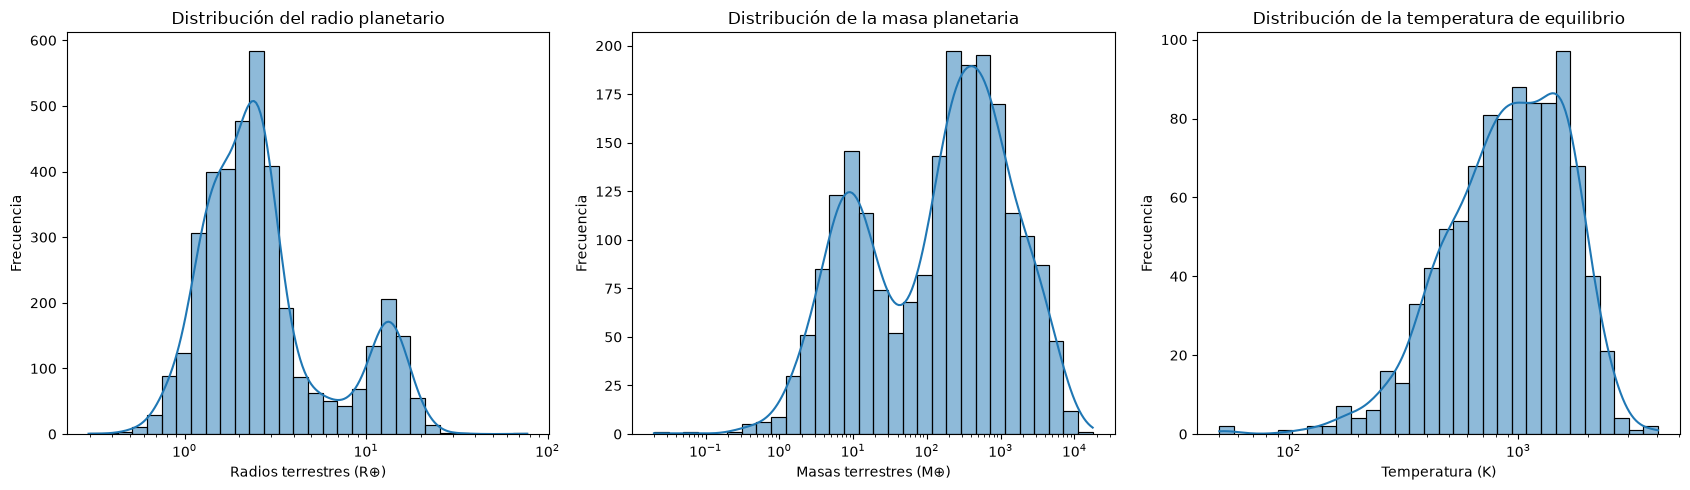

In [30]:
#Distribución de variables físicas
import matplotlib.pyplot as plt
import seaborn as sns

variables_fisicas = [ #Delimitación de variables a representar
    "pl_rade",
    "pl_bmasse",
    "pl_eqt"
]

titulos = [ #Título de la gráfica
    "Distribución del radio planetario",
    "Distribución de la masa planetaria",
    "Distribución de la temperatura de equilibrio"
]

unidades = [ #Determinación de unidades por gráfico
    "Radios terrestres (R⊕)",
    "Masas terrestres (M⊕)",
    "Temperatura (K)"
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5)) #características de la grafica

for i, variable in enumerate(variables_fisicas): #Ciclo for para la impresión de gráfica

    datos = df_exoplanets[variable].dropna() #Definición de datos a partir de las variables establecidas

    sns.histplot(
        datos,
        bins=30,
        kde=True,
        log_scale=True,
        ax=axes[i]
    )

    axes[i].set_title(titulos[i])
    axes[i].set_xlabel(unidades[i])
    axes[i].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

In [31]:
#Distribución percentil de las variables físicas de los planetas.
resumen_fisico = df_exoplanets[
    variables_fisicas
].describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).T

resumen_fisico

,count,mean,std,min,10%,25%,50%,75%,90%,95%,99%,max
pl_rade,3898.0,4.169603,4.667060,0.296,1.190,1.580,2.3510,3.550,12.442,14.834950,18.88802,77.3420
pl_bmasse,2107.0,718.098860,1333.470870,0.020,5.318,15.385,212.9461,731.009,2071.537,3452.892968,6650.85120,17668.1697
pl_eqt,952.0,1054.629202,568.198755,50.000,410.000,610.750,955.0000,1442.750,1800.000,2064.600000,2581.27000,4050.0000


In [32]:
#Relación entre masa y radio
# Seleccionar las variables de interés
df_masa_radio = df_exoplanets[
    ["pl_name", "hostname", "pl_rade", "pl_bmasse"]
].dropna().copy()

print("Total de planetas con masa y radio:", len(df_masa_radio))

print("Porcentaje respecto al dataset original:",
      round(len(df_masa_radio) / len(df_exoplanets) * 100, 2), "%")

Total de planetas con masa y radio: 976
Porcentaje respecto al dataset original: 19.35 %


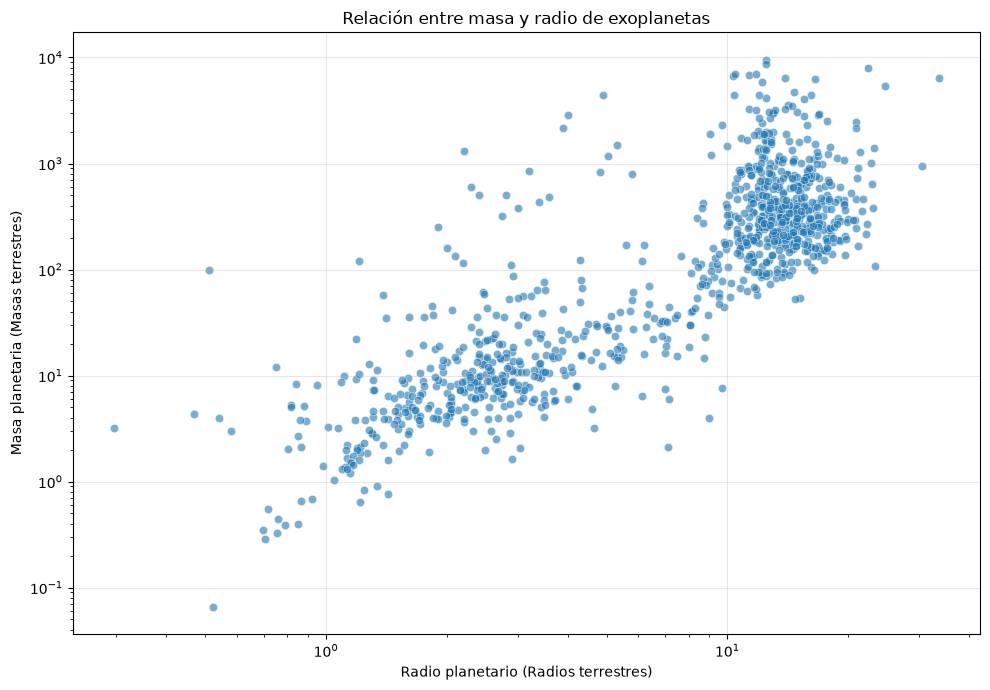

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df_masa_radio,
    x="pl_rade",
    y="pl_bmasse",
    alpha=0.6
)

plt.xscale("log")
plt.yscale("log")

plt.title("Relación entre masa y radio de exoplanetas")
plt.xlabel("Radio planetario (Radios terrestres)")
plt.ylabel("Masa planetaria (Masas terrestres)")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
#Correlación Pearson y Spearman de masa vs radio
correlacion_masa_radio = df_masa_radio[
    ["pl_rade", "pl_bmasse"]
]

print("Pearson:")
display(correlacion_masa_radio.corr(method="pearson"))

print("Spearman:")
display(correlacion_masa_radio.corr(method="spearman"))

Pearson:


,pl_rade,pl_bmasse
pl_rade,1.000000,0.339418
pl_bmasse,0.339418,1.000000


Spearman:


,pl_rade,pl_bmasse
pl_rade,1.000000,0.778218
pl_bmasse,0.778218,1.000000


In [ ]:
#Correlación Pearson logarítmica de masa vs radio
import numpy as np

df_masa_radio["log_radio"] = np.log10(df_masa_radio["pl_rade"])
df_masa_radio["log_masa"] = np.log10(df_masa_radio["pl_bmasse"])

print("Pearson en escala logarítmica:")
display(
    df_masa_radio[["log_radio", "log_masa"]]
    .corr(method="pearson")
)

Pearson en escala logarítmica:


,log_radio,log_masa
log_radio,1.000000,0.844464
log_masa,0.844464,1.000000


In [ ]:
#CORRELACIONES:
#Masa planetaria vs excentricidad orbital
df_masa_excentricidad = df_exoplanets[
    ["pl_name", "hostname", "pl_bmasse", "pl_orbeccen"]
].dropna().copy()


#Masa planetaria vs semieje mayor orbital
df_masa_distancia = df_exoplanets[
    ["pl_name", "hostname", "pl_bmasse", "pl_orbsmax","discoverymethod"]
].dropna().copy()


#Radio planetario vs semieje mayor orbital
df_radio_distancia = df_exoplanets[
    ["pl_name", "hostname", "pl_rade", "pl_orbsmax","pl_eqt"]
].dropna().copy()

In [37]:
print("Masa planetaria vs excentricidad:", len(df_masa_excentricidad))
print("Masa planetaria vs distancia:", len(df_masa_distancia))
print("Radio planetario vs distancia:", len(df_radio_distancia))

Masa planetaria vs excentricidad: 1672
Masa planetaria vs distancia: 1788
Radio planetario vs distancia: 790


In [39]:
df_masa_excentricidad.describe(
)

,pl_bmasse,pl_orbeccen
count,1672.000000,1672.000000
mean,686.752238,0.158050
std,1275.186407,0.185901
min,0.020000,0.000000
25%,18.687910,0.017000
50%,233.128305,0.090000
75%,719.090375,0.230000
max,17668.169700,0.950000


In [ ]:
#grafica masa planetaria vs excentricidad
import plotly.express as px
import plotly.io as pio
fig2 = px.scatter(
    df_masa_distancia,
    x="pl_bmasse",
    y="pl_orbsmax",
    hover_name="pl_name",
    hover_data=["hostname"],
    log_x=True,
    log_y=True,
    title="Masa planetaria vs Semieje mayor orbital",
    labels={
        "pl_bmasse": "Masa planetaria (Masas terrestres)",
        "pl_orbsmax": "Distancia a la estrella (AU)"
    },
    opacity=0.65
)

fig2.update_layout(
    template="plotly_white",
    height=600
)

fig2.show()

In [ ]:
#Gráfica optimizada de Masa Planetaria vs Semieje Mayor Orbital
fig2 = px.scatter(
    df_masa_distancia,
    x="pl_bmasse",
    y="pl_orbsmax",
    color="pl_bmasse",           # El color cambia según la masa planetaria
    size="pl_bmasse",            # El tamaño del punto cambia con la masa
    size_max=18,                 # Controla el tamaño máximo de los círculos
    hover_name="pl_name",
    hover_data={
        "hostname": True,        # Muestra la estrella
        "pl_bmasse": ":.2f",     # Formatea la masa a 2 decimales
        "pl_orbsmax": ":.3f"     # Formatea la distancia a 3 decimales
    },
    log_x=True,
    log_y=True,
    title="<b>Masa Planetaria vs. Semieje Mayor Orbital</b><br><span style='font-size:13px; color:gray;'>Explorando la distribución y escala de los exoplanetas descubiertos</span>",
    labels={
        "pl_bmasse": "Masa Planetaria (M☉)",
        "pl_orbsmax": "Distancia a la Estrella (AU)",
        "hostname": "Estrella Anfitriona"
    },
    color_continuous_scale=px.colors.sequential.Viridis, # Paleta moderna y accesible
    opacity=0.75
)

#Ajustes de diseño
fig2.update_layout(
    template="plotly_white",
    height=650,
    font=dict(family="Arial, sans-serif", size=12),
    margin=dict(l=60, r=40, t=80, b=60),
    coloraxis_showscale=False,  # Oculta la barra de color para no saturar el diseño
)

#Refinamiento de ejes y cuadrícula
fig2.update_xaxes(
    showgrid=True, 
    gridwidth=1, 
    gridcolor="#EBEBEB", 
    zeroline=False,
    title_font=dict(size=14, family="Arial, sans-serif")
)

fig2.update_yaxes(
    showgrid=True, 
    gridwidth=1, 
    gridcolor="#EBEBEB", 
    zeroline=False,
    title_font=dict(size=14, family="Arial, sans-serif")
)

fig2.show()

In [ ]:
#Filtración para quedarse solo con los métodos principales
metodos_principales = df_masa_distancia['discoverymethod'].value_counts().nlargest(5).index
df_filtrado = df_masa_distancia[df_masa_distancia['discoverymethod'].isin(metodos_principales)]

fig = px.scatter(
    df_filtrado, 
    x="pl_bmasse", 
    y="pl_orbsmax", 
    facet_col="discoverymethod",   # Mantenemos la separación por columnas...
    facet_col_wrap=3,              # Máximo 3 columnas por fila, el resto va abajo
    log_x=True, 
    log_y=True,
    opacity=0.6,
    color="discoverymethod",       # Añade color por método para diferenciar mejor las poblaciones
    title="<b>Poblaciones de Exoplanetas por Método de Descubrimiento</b><br><span style='font-size:13px; color:gray;'>Análisis de sesgos de selección en la detección planetaria</span>",
    labels={
        "pl_bmasse": "Masa Planetaria (M☉)",
        "pl_orbsmax": "Distancia a la Estrella (AU)",
        "discoverymethod": "Método"
    },
    template="plotly_white",
    height=800                     # Incrementamos la altura para dar espacio a las filas
)

# 2. Limpieza de textos encimados y formato de títulos de cada recuadro
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1])) # Quita el molesto "discoverymethod=" del título

# Ajustes de diseño de los ejes para que no se dupliquen ni se encimen
fig.update_xaxes(showgrid=True, gridcolor="#EBEBEB", tickangle=0)
fig.update_yaxes(showgrid=True, gridcolor="#EBEBEB")

# Ajustar márgenes para que los títulos largos no se corten
fig.update_layout(
    margin=dict(t=100, b=80, l=80, r=40),
    font=dict(family="Arial, sans-serif", size=11),
    showlegend=False # Ocultamos la leyenda ya que el título de cada recuadro dice el método
)

fig.show()

In [ ]:
# Radio Planetario vs Distancia orbital (semieje mayor)
fig3 = px.scatter(
    df_radio_distancia,
    x="pl_rade",
    y="pl_orbsmax",
    hover_name="pl_name",
    hover_data=["hostname"],
    log_x=True,
    log_y=True,
    title="Radio planetario vs Distancia orbital",
    labels={
        "pl_rade": "Radio planetario (Radios terrestres)",
        "pl_orbsmax": "SDistancia orbital (AU)"
    },
    opacity=0.65
)

fig3.update_layout(
    template="plotly_white",
    height=600
)

fig3.show()

In [ ]:
import plotly.express as px

fig1 = px.scatter(
    df_radio_distancia,
    x="pl_rade",
    y="pl_orbsmax",
    hover_name="pl_name",
    hover_data=["hostname"],
    log_x=True,
    log_y=True,
    title="<b>Radio Planetaria vs. Distancia Orbital</b>",
    labels={
        "pl_rade": "Radio Planetario (Radios Terrestres)",
        "pl_orbsmax": "Distancia orbital (AU)"
    },
    opacity=0.6,
    template="plotly_white"
)
fig1.show()


In [ ]:
import numpy as np
import plotly.express as px
from scipy.stats import spearmanr

# Preparación de datos
df_radio_distancia = df_exoplanets[
    ["pl_name", "hostname", "pl_rade", "pl_orbsmax", "pl_eqt"]
].dropna().copy()

# CÁLCULO DE LA CORRELACIÓN DE SPEARMAN
# Usamos Spearman porque la relación entre distancia orbital y temperatura es puramente curva (exponencial inversa)
coef_spearman, p_valor = spearmanr(df_radio_distancia['pl_orbsmax'], df_radio_distancia['pl_eqt'])

print(f"Coeficiente de correlación de Spearman: {coef_spearman:.4f}")
print(f"P-valor: {p_valor}")

# Categorización de planetas por radio (Mantenemos tu lógica para el hover)
condiciones = [
    (df_radio_distancia['pl_rade'] < 1.25),
    (df_radio_distancia['pl_rade'] >= 1.25) & (df_radio_distancia['pl_rade'] < 2.0),
    (df_radio_distancia['pl_rade'] >= 2.0) & (df_radio_distancia['pl_rade'] < 6.0),
    (df_radio_distancia['pl_rade'] >= 6.0)
]
categorias = ['Rocoso (Tipo Tierra)', 'Súper-Tierra', 'Tipo Neptuno', 'Gigante Gaseoso (Tipo Júpiter)']
df_radio_distancia['tipo_planeta'] = np.select(condiciones, categorias, default='Desconocido')

#GENERACIÓN DE GRÁFICA OPTIMIZADA
subtitulo = (
    "Correlación entre Radio, Distancia Orbital y Temperatura de Equilibrio.<br>"
    f"<b>Análisis estadístico:</b> Coeficiente de Spearman = {coef_spearman:.2f} (Relación inversa muy fuerte)."
)

fig3 = px.scatter(
    df_radio_distancia,
    x="pl_rade",
    y="pl_orbsmax",
    color="pl_eqt",                 
    color_continuous_scale="thermal",
    hover_name="pl_name",
    hover_data={
        "hostname": True,
        "tipo_planeta": True,
        "pl_eqt": ":.0f K"          
    },
    log_x=True,
    log_y=True,
    title="<b>Influencia Térmica en el Tamaño y Órbita de Exoplanetas</b>",
    labels={
        "pl_rade": "Radio Planetario (Radios Terrestres)",
        "pl_orbsmax": "Distancia a la Estrella (AU)",
        "pl_eqt": "Temperatura",
        "tipo_planeta": "Categoría Física"
    },
    template="plotly_white",
    opacity=0.75
)

#AÑADIR LÍNEAS DE REFERENCIA DE LA TIERRA
# Línea vertical para el Radio de la Tierra (1 R_earth)
fig3.add_vline(
    x=1.0, 
    line_width=1.5, 
    line_dash="dash", 
    line_color="#4A5568",
    annotation_text=" Radio de la Tierra", 
    annotation_position="top left"
)

# Línea horizontal para la Distancia de la Tierra (1 AU)
fig3.add_hline(
    y=1.0, 
    line_width=1.5, 
    line_dash="dash", 
    line_color="#4A5568",
    annotation_text=" Órbita de la Tierra (1 AU)", 
    annotation_position="top right"
)

#AJUSTES DE DISEÑO Y LEYENDAS
fig3.update_layout(
    height=650,
    font=dict(family="Arial, sans-serif", size=12),
    margin=dict(l=60, r=40, t=110, b=120),
    title_text=f"<b>Influencia Térmica en el Tamaño y Órbita de Exoplanetas</b><br><span style='font-size:13px; color:gray;'>{subtitulo}</span>",
    
    # Barra de color horizontal en la parte inferior
    coloraxis_colorbar=dict(
        title="Temperatura de Equilibrio (K)",
        orientation="h",
        yanchor="bottom", y=-0.25,
        xanchor="center", x=0.5,
        thickness=15,
        len=0.6
    )
)

fig3.update_traces(marker=dict(size=7))

fig3.show()


Coeficiente de correlación de Spearman: -0.4963
P-valor: 2.3376966602680935e-50


In [47]:
df_excentricidad_distancia = df_exoplanets[
    ["pl_name", "hostname", "pl_orbeccen", "pl_orbsmax", "pl_rade", "pl_eqt"]
].dropna().copy()

print("Número de observaciones:", len(df_excentricidad_distancia))

Número de observaciones: 522


In [ ]:
import plotly.express as px

# pl_orbper en selección, limpiar nulos
df_arquitectura = df_exoplanets[
    ["pl_name", "hostname", "pl_orbper", "pl_orbeccen", "pl_rade", "pl_eqt"]
].dropna().copy()

#Gráfica principal
fig = px.scatter(
    df_arquitectura,
    x="pl_orbper",                  # Periodo Orbital en el eje X
    y="pl_orbeccen",
    color="pl_eqt",                 
    size="pl_rade",                 
    size_max=15,                    
    hover_name="pl_name",
    hover_data={
        "hostname": True,
        "pl_rade": ":.2f",
        "pl_eqt": ":.0f K",
        "pl_orbper": ":.2f"         
    },
    log_x=True,                     # Escala logarítmica para los días del periodo
    title="<b>Estabilidad Orbital: Excentricidad vs. Periodo Orbital</b><br><span style='font-size:13px; color:gray;'>Relación entre la duración del año planetario, las fuerzas de marea y la excentricidad</span>",
    labels={
        "pl_orbper": "Periodo Orbital (Días Terrestres)",
        "pl_orbeccen": "Excentricidad Orbital",
        "pl_eqt": "Temperatura (K)"
    },
    color_continuous_scale="plasma", 
    opacity=0.7,
    template="plotly_white",
    height=650
)

#Añadir la posición de la Tierra usando add_scatter directo
fig.add_scatter(
    x=[365.25], 
    y=[0.016],
    mode="markers",
    marker=dict(
        size=14, 
        color="cyan", 
        symbol="star", 
        line=dict(width=2, color="black")
    ),
    name="La Tierra 🌍",
    showlegend=True
)

# 4. Ajustes de diseño de ejes y leyendas
fig.update_layout(
    margin=dict(l=60, r=40, t=90, b=120),
    font=dict(family="Arial, sans-serif", size=12),
    coloraxis_colorbar=dict(
        title="Temp. (K)",
        orientation="h",
        yanchor="bottom", y=-0.25,
        xanchor="center", x=0.5,
        thickness=15,
        len=0.6
    )
)

fig.update_yaxes(range=[-0.05, 1.05])

fig.show()


In [49]:
df_sistemas = (
    df_exoplanets
    .groupby("hostname", as_index=False)
    .agg(
        masa_estelar=("st_mass", "median"),
        temperatura_planetar=("pl_eqt", "first")
    )
)

# Excluir únicamente los sistemas sin masa estelar disponible
df_sistemas = df_sistemas.dropna(
    subset=["masa_estelar", "temperatura_planetar"]
).copy()

print("Total de sistemas analizados:", len(df_sistemas))
df_sistemas.head()

Total de sistemas analizados: 766


,hostname,masa_estelar,temperatura_planetar
7,1RXS J160929.1-210524,0.85,1700.0
13,2MASS J04372171+2651014,0.17,1450.0
15,2MASS J12073346-3932539,0.02,1250.0
17,2MASS J21402931+1625183 A,0.08,2075.0
23,51 Eri,1.75,700.0


In [ ]:
#Temperatura planetaria vs Masa estelar
import plotly.express as px

fig = px.scatter(
    df_sistemas,
    x="masa_estelar",
    y="temperatura_planetar",
    hover_name="hostname",
    hover_data={
        "masa_estelar": ":.3f",
        "temperatura_planetar": True
    },
    log_x=True,
    title="Cantidad de exoplanetas vs Masa de la estrella anfitriona",
    labels={
        "masa_estelar": "Masa estelar (Masas solares)",
        "temperatura_planetar": "temperatura de planetas conocidos"
    },
    opacity=0.65
)

fig.update_layout(
    template="plotly_white",
    height=650,
    xaxis_title="Masa de la estrella (M☉)",
    yaxis_title="Temperatura de planetas"
)

fig.show()